# Lab 04 – Fine-Tuning a Large Language Model using LoRA

## Introduction

This practical demonstrates Parameter-Efficient Fine-Tuning (PEFT) by adapting a pre-trained Large Language Model (LLM) to a domain-specific customer-support task.

The experiment uses **Qwen2.5-0.5B-Instruct** and a custom dataset for a fictional computer shop named **TechZone Computers**. The model is fine-tuned with **LoRA** using Hugging Face TRL's `SFTTrainer`. The original and fine-tuned models are evaluated on the same held-out test questions.

> **Scope note:** The required practical is completed using LoRA. QLoRA is an optional extension in the lab instructions; this notebook does not claim to run a QLoRA experiment.

### Objectives

- Identify the available GPU and software environment.
- Prepare at least 30 domain-specific question-and-answer examples.
- Load an instruction-tuned causal language model.
- Configure LoRA using PEFT.
- Perform supervised fine-tuning using TRL `SFTTrainer`.
- Compare the original and fine-tuned models on identical unseen test questions.
- Interpret training and evaluation results, including limitations.

### Development environment

- **Domain:** Fictional computer-shop customer support
- **Dataset:** 50 question-and-answer pairs (kept at the original size; the lab minimum is 30)
- **Base model:** `Qwen/Qwen2.5-0.5B-Instruct`
- **Fine-tuning method:** LoRA
- **Training framework:** Hugging Face TRL `SFTTrainer`

## Import Libraries

In [1]:
import torch
import platform
import os

print("Python Version:", platform.python_version())
print("PyTorch Version:", torch.__version__)

# Check CUDA availability
print("\nCUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():

    # Get GPU information
    gpu_name = torch.cuda.get_device_name(0)

    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print("GPU:", gpu_name)
    print(f"GPU Memory: {gpu_memory:.2f} GB")

    print("CUDA Version:", torch.version.cuda)

else:
    print("No GPU detected. Please enable GPU runtime.")

print("\nCPU Information:")
print("CPU Cores:", os.cpu_count())

Python Version: 3.13.16
PyTorch Version: 2.14.1+cu130

CUDA Available: True
GPU: Tesla T4
GPU Memory: 14.56 GB
CUDA Version: 13.0

CPU Information:
CPU Cores: 2


In [2]:
# Install the required libraries

!pip install -q -U \
    transformers \
    datasets \
    peft \
    trl \
    accelerate \
    bitsandbytes \
    evaluate \
    sacrebleu \
    rouge_score

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


### Verify library installations

In [3]:
import transformers
import datasets
import peft
import trl
import accelerate
import bitsandbytes

print("Library Installation Verification")
print("-----------------------------------")

print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("PEFT:", peft.__version__)
print("TRL:", trl.__version__)
print("Accelerate:", accelerate.__version__)
print("BitsAndBytes:", bitsandbytes.__version__)

print("\nAll required libraries imported successfully!")

Library Installation Verification
-----------------------------------
Transformers: 5.23.0
Datasets: 5.2.0
PEFT: 0.21.3
TRL: 1.18.0
Accelerate: 1.15.0
BitsAndBytes: 0.50.2

All required libraries imported successfully!


### Dataset Creation

A custom dataset is created to represent a fictional computer shop named **TechZone Computers**.

The dataset contains customer questions and predefined responses related to the shop's products and services.

Each record consists of:
- **Question:** A customer query.
- **Answer:** The corresponding customer-support response.
- **Category:** The subject area of the question.

The category field helps organize and inspect the dataset. The question-and-answer content will be used for model fine-tuning.

In [4]:
data = [

    # 1. Products
    {
        "question": "What products do you sell?",
        "answer": "TechZone Computers sells laptops, desktop computers, monitors, keyboards, mice, printers and computer accessories.",
        "category": "Products"
    },
    {
        "question": "Do you sell gaming laptops?",
        "answer": "Yes, TechZone Computers offers selected gaming laptop models.",
        "category": "Products"
    },
    {
        "question": "Can I purchase a desktop computer?",
        "answer": "Yes, desktop computers are available in different configurations.",
        "category": "Products"
    },
    {
        "question": "Do you have wireless keyboards?",
        "answer": "Yes, wireless keyboards are available in selected models.",
        "category": "Products"
    },
    {
        "question": "Do you sell computer monitors?",
        "answer": "Yes, we sell computer monitors in different screen sizes.",
        "category": "Products"
    },

    # 2. Pricing
    {
        "question": "How much does a basic laptop cost?",
        "answer": "A basic laptop starts at LKR 150,000.",
        "category": "Pricing"
    },
    {
        "question": "What is the price of a wireless mouse?",
        "answer": "A standard wireless mouse costs LKR 2,500.",
        "category": "Pricing"
    },
    {
        "question": "How much is a 24-inch monitor?",
        "answer": "A standard 24-inch monitor costs LKR 45,000.",
        "category": "Pricing"
    },
    {
        "question": "What is the price of a gaming laptop?",
        "answer": "Gaming laptops start at LKR 250,000.",
        "category": "Pricing"
    },
    {
        "question": "How much does a mechanical keyboard cost?",
        "answer": "A standard mechanical keyboard costs LKR 8,500.",
        "category": "Pricing"
    },

    # 3. Warranty
    {
        "question": "Do laptops come with a warranty?",
        "answer": "Yes, laptops include a one-year manufacturer warranty.",
        "category": "Warranty"
    },
    {
        "question": "How long is the desktop computer warranty?",
        "answer": "Desktop computers include a one-year warranty.",
        "category": "Warranty"
    },
    {
        "question": "Does the warranty cover physical damage?",
        "answer": "Physical damage caused by accidents or misuse is not covered under the standard warranty.",
        "category": "Warranty"
    },
    {
        "question": "Can I claim warranty without a receipt?",
        "answer": "Customers should provide the original purchase receipt when requesting warranty service.",
        "category": "Warranty"
    },
    {
        "question": "Are accessories covered by warranty?",
        "answer": "Selected accessories include a three-month warranty.",
        "category": "Warranty"
    },

    # 4. Repairs
    {
        "question": "Do you provide laptop repair services?",
        "answer": "Yes, we provide laptop diagnostic and repair services.",
        "category": "Repairs"
    },
    {
        "question": "Can you replace a broken laptop screen?",
        "answer": "Yes, laptop screen replacement is available depending on the model and spare part availability.",
        "category": "Repairs"
    },
    {
        "question": "How long does a laptop repair take?",
        "answer": "Most standard repairs take between two and five working days.",
        "category": "Repairs"
    },
    {
        "question": "Do you provide computer cleaning services?",
        "answer": "Yes, we provide internal dust cleaning and basic computer maintenance.",
        "category": "Repairs"
    },
    {
        "question": "Can you upgrade my laptop RAM?",
        "answer": "Yes, RAM upgrades are available for compatible laptop models.",
        "category": "Repairs"
    },

    # 5. Payments
    {
        "question": "What payment methods do you accept?",
        "answer": "We accept cash, debit cards and credit cards.",
        "category": "Payments"
    },
    {
        "question": "Can I pay using a credit card?",
        "answer": "Yes, customers can pay using supported credit cards.",
        "category": "Payments"
    },
    {
        "question": "Do you accept bank transfers?",
        "answer": "Yes, bank transfers are accepted for customer purchases.",
        "category": "Payments"
    },
    {
        "question": "Can I pay in cash?",
        "answer": "Yes, cash payments are accepted at our store.",
        "category": "Payments"
    },
    {
        "question": "Do you provide instalment payments?",
        "answer": "Yes, instalment payment options are available for selected credit cards.",
        "category": "Payments"
    },

    # 6. Returns and Exchanges
    {
        "question": "Can I return a damaged product?",
        "answer": "Yes, customers can request an exchange for a damaged product within seven days of purchase with the original receipt.",
        "category": "Returns"
    },
    {
        "question": "Can I exchange a product?",
        "answer": "Yes, eligible products can be exchanged within seven days of purchase.",
        "category": "Returns"
    },
    {
        "question": "Do I need the original receipt for a return?",
        "answer": "Yes, the original purchase receipt is required for return and exchange requests.",
        "category": "Returns"
    },
    {
        "question": "Can I return a product after 30 days?",
        "answer": "The standard return period is seven days. Requests outside this period are not covered by the standard return policy.",
        "category": "Returns"
    },
    {
        "question": "Can I return a product that I have used?",
        "answer": "Used products are not eligible for standard returns unless they qualify under the applicable warranty or consumer protection policy.",
        "category": "Returns"
    },

    # 7. Delivery
    {
        "question": "Do you provide home delivery?",
        "answer": "Yes, we provide home delivery services within selected areas.",
        "category": "Delivery"
    },
    {
        "question": "How long does delivery take?",
        "answer": "Standard deliveries usually take two to four working days.",
        "category": "Delivery"
    },
    {
        "question": "Is delivery free?",
        "answer": "Free delivery is available for orders above LKR 50,000 within selected delivery areas.",
        "category": "Delivery"
    },
    {
        "question": "Can I track my order?",
        "answer": "Yes, customers receive an order tracking reference after their order is dispatched.",
        "category": "Delivery"
    },
    {
        "question": "Do you deliver outside Colombo?",
        "answer": "Yes, deliveries are available to selected locations outside Colombo.",
        "category": "Delivery"
    },

    # 8. Store Information
    {
        "question": "Where is TechZone Computers located?",
        "answer": "TechZone Computers is located at No. 25, Main Street, Colombo 03, Sri Lanka.",
        "category": "Store Information"
    },
    {
        "question": "What time does the shop open?",
        "answer": "The shop opens at 9:00 AM from Monday to Saturday.",
        "category": "Store Information"
    },
    {
        "question": "What time does the shop close?",
        "answer": "The shop closes at 6:00 PM from Monday to Saturday.",
        "category": "Store Information"
    },
    {
        "question": "Is the shop open on Sundays?",
        "answer": "No, TechZone Computers is closed on Sundays.",
        "category": "Store Information"
    },
    {
        "question": "Can I contact the shop for inquiries?",
        "answer": "Yes, customers can contact the store during business hours for product and service inquiries.",
        "category": "Store Information"
    },

    # 9. Technical Support
    {
        "question": "My laptop is running slowly. What should I do?",
        "answer": "Try restarting your laptop, closing unnecessary applications and checking available storage space. You can contact our technical team if the problem continues.",
        "category": "Technical Support"
    },
    {
        "question": "What should I do if my computer does not turn on?",
        "answer": "Check the power connection, charger and power outlet. If the computer still does not turn on, contact our technical support team.",
        "category": "Technical Support"
    },
    {
        "question": "Can you install Windows on my laptop?",
        "answer": "Yes, we provide operating system installation services for compatible computers.",
        "category": "Technical Support"
    },
    {
        "question": "Do you install antivirus software?",
        "answer": "Yes, we provide antivirus software installation assistance.",
        "category": "Technical Support"
    },
    {
        "question": "Can you help with Wi-Fi connection problems?",
        "answer": "Yes, our technical team can diagnose and assist with common Wi-Fi connectivity problems.",
        "category": "Technical Support"
    },

    # 10. Orders and Reservations
    {
        "question": "Can I reserve a laptop?",
        "answer": "Yes, customers can request a laptop reservation by contacting the store.",
        "category": "Orders"
    },
    {
        "question": "Can I check product availability before visiting?",
        "answer": "Yes, customers can contact the store to confirm product availability.",
        "category": "Orders"
    },
    {
        "question": "Can I cancel an order?",
        "answer": "Customers can request order cancellation before the order is dispatched.",
        "category": "Orders"
    },
    {
        "question": "Will I receive an order confirmation?",
        "answer": "Yes, customers receive an order confirmation after a purchase is successfully placed.",
        "category": "Orders"
    },
    {
        "question": "Can I modify my order after placing it?",
        "answer": "Customers can contact the store to request order modifications before dispatch.",
        "category": "Orders"
    }
]

print("Dataset created successfully!")
print("Total question-answer pairs:", len(data))

Dataset created successfully!
Total question-answer pairs: 50


### Convert dataset into a DataFrame

In [5]:
import pandas as pd

# Convert the dataset into a Pandas DataFrame
df = pd.DataFrame(data)

# Display the first 10 records
display(df.head(10))

# Display dataset information
print("\nDataset Information")
print("-------------------")

print("Total records:", len(df))
print("Total columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

,question,answer,category
0,What products do you sell?,"TechZone Computers sells laptops, desktop comp...",Products
1,Do you sell gaming laptops?,"Yes, TechZone Computers offers selected gaming...",Products
2,Can I purchase a desktop computer?,"Yes, desktop computers are available in differ...",Products
3,Do you have wireless keyboards?,"Yes, wireless keyboards are available in selec...",Products
4,Do you sell computer monitors?,"Yes, we sell computer monitors in different sc...",Products
5,How much does a basic laptop cost?,"A basic laptop starts at LKR 150,000.",Pricing
6,What is the price of a wireless mouse?,"A standard wireless mouse costs LKR 2,500.",Pricing
7,How much is a 24-inch monitor?,"A standard 24-inch monitor costs LKR 45,000.",Pricing
8,What is the price of a gaming laptop?,"Gaming laptops start at LKR 250,000.",Pricing
9,How much does a mechanical keyboard cost?,"A standard mechanical keyboard costs LKR 8,500.",Pricing



Dataset Information
-------------------
Total records: 50
Total columns: 3

Column names:
['question', 'answer', 'category']

Missing values:
question    0
answer      0
category    0
dtype: int64


### Dataset validation

The lab requires at least 30 domain-specific question-and-answer pairs. This experiment retains all **50 original examples**. The checks below verify the dataset size, required fields, missing values, and duplicate questions before splitting.

In [6]:
# Validate the original 50-example dataset without adding or removing examples
required_columns = {"question", "answer", "category"}
assert required_columns.issubset(df.columns), "Dataset is missing required columns."
assert len(df) >= 30, "The dataset must contain at least 30 examples."
assert df["question"].notna().all() and df["answer"].notna().all()
assert df["question"].str.strip().ne("").all()
assert df["answer"].str.strip().ne("").all()

print("Dataset validation passed")
print("Total examples:", len(df))
print("Meets lab minimum (30):", len(df) >= 30)
print("Duplicate questions:", df["question"].duplicated().sum())

Dataset validation passed
Total examples: 50
Meets lab minimum (30): True
Duplicate questions: 0


## Explore dataset categories

category
Products             5
Pricing              5
Warranty             5
Repairs              5
Payments             5
Returns              5
Delivery             5
Store Information    5
Technical Support    5
Orders               5
Name: count, dtype: int64


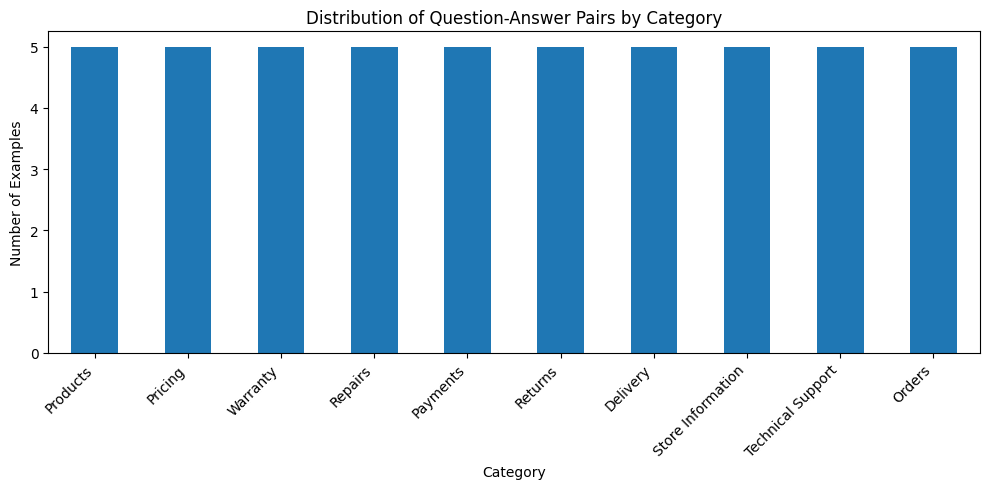

In [7]:
import matplotlib.pyplot as plt

# Count records in each category
category_counts = df["category"].value_counts()

print(category_counts)

# Visualize category distribution
plt.figure(figsize=(10, 5))

category_counts.plot(kind="bar")

plt.title("Distribution of Question-Answer Pairs by Category")
plt.xlabel("Category")
plt.ylabel("Number of Examples")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

## Split the dataset

In [8]:
from datasets import Dataset

# Convert all 50 examples into a Hugging Face Dataset
hf_dataset = Dataset.from_pandas(df, preserve_index=False)

# Split into 80% training, 10% validation and 10% testing
train_test = hf_dataset.train_test_split(test_size=0.20, seed=42)
train_dataset = train_test["train"]
temp_dataset = train_test["test"]

validation_test = temp_dataset.train_test_split(test_size=0.50, seed=42)
validation_dataset = validation_test["train"]
test_dataset = validation_test["test"]

print("Dataset Splitting Results")
print("-------------------------")
print("Training examples:", len(train_dataset))
print("Validation examples:", len(validation_dataset))
print("Testing examples:", len(test_dataset))
print("Total examples:", len(train_dataset) + len(validation_dataset) + len(test_dataset))

assert len(train_dataset) + len(validation_dataset) + len(test_dataset) == len(df)

# Inspect category coverage in each split. With a small dataset, some categories
# may not appear in every split; this is reported rather than silently altered.
for split_name, split_data in [
    ("Training", train_dataset),
    ("Validation", validation_dataset),
    ("Testing", test_dataset)
]:
    counts = pd.Series(split_data["category"]).value_counts().sort_index()
    print(f"\n{split_name} category counts:")
    display(counts.to_frame("examples"))

Dataset Splitting Results
-------------------------
Training examples: 40
Validation examples: 5
Testing examples: 5
Total examples: 50

Training category counts:


,examples
Delivery,5
Orders,1
Payments,4
Pricing,4
Products,5
Repairs,4
Returns,3
Store Information,4
Technical Support,5
Warranty,5



Validation category counts:


,examples
Orders,1
Payments,1
Repairs,1
Returns,1
Store Information,1



Testing category counts:


,examples
Orders,3
Pricing,1
Returns,1


In [9]:
#Inspect the split datasets

print("Training Dataset Sample:")
print(train_dataset[0])

print("\nValidation Dataset Sample:")
print(validation_dataset[0])

print("\nTesting Dataset Sample:")
print(test_dataset[0])

Training Dataset Sample:
{'question': 'What time does the shop close?', 'answer': 'The shop closes at 6:00 PM from Monday to Saturday.', 'category': 'Store Information'}

Validation Dataset Sample:
{'question': 'What payment methods do you accept?', 'answer': 'We accept cash, debit cards and credit cards.', 'category': 'Payments'}

Testing Dataset Sample:
{'question': 'Do I need the original receipt for a return?', 'answer': 'Yes, the original purchase receipt is required for return and exchange requests.', 'category': 'Returns'}


###**Pretrained** **Model** **Selection**

The Qwen2.5-0.5B-Instruct model is selected as the base language model for this experiment.

It is an instruction-tuned model containing approximately 0.5 billion parameters. Its relatively small size makes it suitable for parameter-efficient fine-tuning experiments in a GPU-constrained environment.

The model and its corresponding tokenizer will be retrieved from the Hugging Face Model Hub.

In [10]:
# Define the pretrained model

model_name = "Qwen/Qwen2.5-0.5B-Instruct"

print("Selected Model:", model_name)

Selected Model: Qwen/Qwen2.5-0.5B-Instruct


### Initialize tokenizer

In [11]:
from transformers import AutoTokenizer

# Load the tokenizer associated with the pretrained model
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Configure padding token if required
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Tokenizer loaded successfully!")

print("Vocabulary Size:", tokenizer.vocab_size)
print("Padding Token:", tokenizer.pad_token)
print("EOS Token:", tokenizer.eos_token)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Tokenizer loaded successfully!
Vocabulary Size: 151643
Padding Token: <|endoftext|>
EOS Token: <|im_end|>


### Load pretrained model

In [12]:
import torch
import gc
from transformers import AutoModelForCausalLM

# Check GPU compute capability
major, minor = torch.cuda.get_device_capability(0)

print("GPU:", torch.cuda.get_device_name(0))
print("Compute Capability:", f"{major}.{minor}")

# Select supported numerical precision
if major >= 8:
    dtype = torch.bfloat16
else:
    dtype = torch.float16

print("Selected Precision:", dtype)

# Release previously loaded model if available
if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

# Load pretrained model using selected precision
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    dtype=dtype,
    device_map="auto"
)

print("\nPretrained model loaded successfully!")
print("Model Device:", model.device)
print("Model Data Type:", next(model.parameters()).dtype)
print("Total Parameters:", f"{model.num_parameters():,}")

GPU: Tesla T4
Compute Capability: 7.5
Selected Precision: torch.float16


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]


Pretrained model loaded successfully!
Model Device: cuda:0
Model Data Type: torch.float16
Total Parameters: 494,032,768


## Inspect model architecture

In [13]:
# Display model configuration

print("Model Architecture")
print("------------------")

print("Model Type:", model.config.model_type)
print("Hidden Size:", model.config.hidden_size)
print("Number of Layers:", model.config.num_hidden_layers)
print("Attention Heads:", model.config.num_attention_heads)
print("Vocabulary Size:", model.config.vocab_size)

# Calculate model parameters
total_parameters = model.num_parameters()

print("\nTotal Parameters:", f"{total_parameters:,}")

# Calculate trainable parameters
trainable_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Trainable Parameters:", f"{trainable_parameters:,}")

Model Architecture
------------------
Model Type: qwen2
Hidden Size: 896
Number of Layers: 24
Attention Heads: 14
Vocabulary Size: 151936

Total Parameters: 494,032,768
Trainable Parameters: 494,032,768


## Define the generation function

In [14]:
def generate_answer(model, question):

    # Format the customer question
    messages = [
        {
            "role": "user",
            "content": question
        }
    ]

    # Apply the model's chat template
    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    # Convert text into model input tensors
    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    # Generate the response
    model.eval()

    with torch.no_grad():

        outputs = model.generate(
            **inputs,
            max_new_tokens=120,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id
        )

    # Extract only newly generated tokens
    new_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    # Convert generated tokens into text
    answer = tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    )

    return answer.strip()

## Test the original pretrained model

In [15]:
# Store original model responses
original_answers = []

print("Original Model - Baseline Testing")
print("=" * 60)

for example in test_dataset:

    question = example["question"]

    # Generate response using the original model
    answer = generate_answer(model, question)

    original_answers.append(answer)

    print("\nQuestion:", question)
    print("Expected Answer:", example["answer"])
    print("Generated Answer:", answer)

    print("-" * 60)

Original Model - Baseline Testing

Question: Do I need the original receipt for a return?
Expected Answer: Yes, the original purchase receipt is required for return and exchange requests.
Generated Answer: In most cases, you do not necessarily need an original receipt to return something. However, there are some situations where it might be necessary:

1. **Shipping Receipts**: If you received a shipping receipt from the seller or a third-party service provider, it's usually sufficient to have this document as proof of delivery.

2. **Returns Policy**: Some sellers may have specific returns policies that require additional documentation such as receipts or invoices. Always check their policy and ask if they require any additional information.

3. **Payment Method**: If you used a payment method other than credit card (e.g.,
------------------------------------------------------------

Question: Can I cancel an order?
Expected Answer: Customers can request order cancellation before the 

## Store baseline results

In [16]:
# Create a DataFrame containing baseline results

baseline_results = pd.DataFrame({

    "Question": test_dataset["question"],

    "Expected Answer": test_dataset["answer"],

    "Original Model Response": original_answers

})

display(baseline_results)

,Question,Expected Answer,Original Model Response
0,Do I need the original receipt for a return?,"Yes, the original purchase receipt is required...","In most cases, you do not necessarily need an ..."
1,Can I cancel an order?,Customers can request order cancellation befor...,"Yes, you can cancel an order. To do so, follow..."
2,How much does a basic laptop cost?,"A basic laptop starts at LKR 150,000.",The price of a basic laptop can vary widely de...
3,Can I reserve a laptop?,"Yes, customers can request a laptop reservatio...","Yes, you can reserve a laptop! To do so, you'l..."
4,Can I modify my order after placing it?,Customers can contact the store to request ord...,"Yes, you can modify your order after placing i..."


# Dataset Formatting and Preparation

Before fine-tuning the pretrained language model, the dataset must be converted into a format that the model can understand.

In this experiment, the question-and-answer pairs are transformed into conversational messages using the chat template provided by the Qwen tokenizer.

Each conversation contains two roles:

- **User:** Represents the customer's question.
- **Assistant:** Represents the expected response from the computer shop.

The formatted dataset will be used as input for supervised fine-tuning.

### Convert dataset into conversational messages

In [17]:
# Convert question-answer pairs into conversational messages

def format_conversation(example):

    messages = [
        {
            "role": "user",
            "content": example["question"]
        },
        {
            "role": "assistant",
            "content": example["answer"]
        }
    ]

    # Apply Qwen's conversational template
    formatted_text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False
    )

    return {
        "text": formatted_text
    }


print("Conversation formatting function created successfully!")

Conversation formatting function created successfully!


### Apply conversational formatting

In [18]:
# Format all dataset splits

train_formatted = train_dataset.map(
    format_conversation,
    remove_columns=train_dataset.column_names
)

validation_formatted = validation_dataset.map(
    format_conversation,
    remove_columns=validation_dataset.column_names
)

test_formatted = test_dataset.map(
    format_conversation,
    remove_columns=test_dataset.column_names
)

print("Dataset formatting completed!")

print("\nTraining examples:", len(train_formatted))
print("Validation examples:", len(validation_formatted))
print("Testing examples:", len(test_formatted))

Map:   0%|          | 0/40 [00:00<?, ? examples/s]

Map:   0%|          | 0/5 [00:00<?, ? examples/s]

Map:   0%|          | 0/5 [00:00<?, ? examples/s]

Dataset formatting completed!

Training examples: 40
Validation examples: 5
Testing examples: 5


### Inspect formatted conversations

In [19]:
# Display an example from the formatted training dataset

print("Original Question:")
print(train_dataset[0]["question"])

print("\nExpected Answer:")
print(train_dataset[0]["answer"])

print("\nFormatted Conversation:")
print(train_formatted[0]["text"])

Original Question:
What time does the shop close?

Expected Answer:
The shop closes at 6:00 PM from Monday to Saturday.

Formatted Conversation:
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
What time does the shop close?<|im_end|>
<|im_start|>assistant
The shop closes at 6:00 PM from Monday to Saturday.<|im_end|>



## Inspect the formatted dataset

In [20]:
print("Formatted Dataset Information")
print("--------------------------------")

print("Training Dataset:", train_formatted)
print("Validation Dataset:", validation_formatted)
print("Testing Dataset:", test_formatted)

print("\nDataset Columns:", train_formatted.column_names)

# Check for missing formatted conversations
print(
    "\nMissing training conversations:",
    sum(1 for item in train_formatted if not item["text"].strip())
)

Formatted Dataset Information
--------------------------------
Training Dataset: Dataset({
    features: ['text'],
    num_rows: 40
})
Validation Dataset: Dataset({
    features: ['text'],
    num_rows: 5
})
Testing Dataset: Dataset({
    features: ['text'],
    num_rows: 5
})

Dataset Columns: ['text']

Missing training conversations: 0


## LoRA Configuration
### Inspect available target modules

In [21]:
# Identify available LoRA target modules in Qwen

target_modules = [
    "q_proj",
    "k_proj",
    "v_proj",
    "o_proj",
    "gate_proj",
    "up_proj",
    "down_proj"
]

# Find matching modules in the model architecture
available_modules = sorted({
    name.split(".")[-1]
    for name, module in model.named_modules()
    if name.split(".")[-1] in target_modules
})

print("Available Target Modules:")
print("-------------------------")

for module in available_modules:
    print(module)

# Verify all selected modules exist
assert set(target_modules).issubset(set(available_modules)), \
    "Some target modules were not found!"

print("\nAll selected target modules are available!")

Available Target Modules:
-------------------------
down_proj
gate_proj
k_proj
o_proj
q_proj
up_proj
v_proj

All selected target modules are available!


### Create LoRA configuration

In [22]:
from peft import LoraConfig

# Configure LoRA parameters
lora_config = LoraConfig(

    r=8,

    lora_alpha=16,

    lora_dropout=0.05,

    bias="none",

    task_type="CAUSAL_LM",

    target_modules=target_modules
)

print("LoRA configuration created successfully!")

print("\nLoRA Configuration:")
print("-------------------")
print("Rank:", lora_config.r)
print("Alpha:", lora_config.lora_alpha)
print("Dropout:", lora_config.lora_dropout)
print("Scaling Factor:", lora_config.lora_alpha / lora_config.r)
print("Task Type:", lora_config.task_type)
print("Target Modules:", lora_config.target_modules)

LoRA configuration created successfully!

LoRA Configuration:
-------------------
Rank: 8
Alpha: 16
Dropout: 0.05
Scaling Factor: 2.0
Task Type: CAUSAL_LM
Target Modules: {'down_proj', 'gate_proj', 'q_proj', 'o_proj', 'k_proj', 'up_proj', 'v_proj'}


### Apply LoRA to the pretrained model

In [24]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [25]:
from peft import get_peft_model

# Apply LoRA adapters to the pretrained model
model = get_peft_model(
    model,
    lora_config
)

print("LoRA adapters applied successfully!")

# Display trainable and total parameters
model.print_trainable_parameters()

LoRA adapters applied successfully!
trainable params: 4,399,104 || all params: 498,431,872 || trainable%: 0.8826


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


### Parameter comparison

In [26]:
# Calculate total and trainable parameters

total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

# Calculate trainable parameter percentage
trainable_percentage = (
    trainable_params / total_params
) * 100

print("Parameter Analysis")
print("------------------")

print("Total Parameters:", f"{total_params:,}")

print("Trainable Parameters:", f"{trainable_params:,}")

print("Frozen Parameters:", f"{total_params - trainable_params:,}")

print(f"Trainable Percentage: {trainable_percentage:.4f}%")

print(
    f"Frozen Percentage: {100 - trainable_percentage:.4f}%"
)

Parameter Analysis
------------------
Total Parameters: 498,431,872
Trainable Parameters: 4,399,104
Frozen Parameters: 494,032,768
Trainable Percentage: 0.8826%
Frozen Percentage: 99.1174%


# Supervised Fine-Tuning using TRL
## Create prompt-completion datasets

In [27]:
from datasets import Dataset

# Convert question-answer pairs into prompt-completion format
def prepare_sft_example(example):

    return {
        "prompt": [
            {
                "role": "user",
                "content": example["question"]
            }
        ],
        "completion": [
            {
                "role": "assistant",
                "content": example["answer"]
            }
        ]
    }


# Prepare training and validation datasets
sft_train_dataset = train_dataset.map(
    prepare_sft_example,
    remove_columns=train_dataset.column_names
)

sft_validation_dataset = validation_dataset.map(
    prepare_sft_example,
    remove_columns=validation_dataset.column_names
)

print("SFT datasets prepared successfully!")

print("\nTraining examples:", len(sft_train_dataset))
print("Validation examples:", len(sft_validation_dataset))

print("\nSample training example:")
print(sft_train_dataset[0])

Map:   0%|          | 0/40 [00:00<?, ? examples/s]

Map:   0%|          | 0/5 [00:00<?, ? examples/s]

SFT datasets prepared successfully!

Training examples: 40
Validation examples: 5

Sample training example:
{'prompt': [{'role': 'user', 'content': 'What time does the shop close?'}], 'completion': [{'role': 'assistant', 'content': 'The shop closes at 6:00 PM from Monday to Saturday.'}]}


## Verify TRL training configuration support

In [28]:
import inspect
import trl

from trl import SFTTrainer, SFTConfig

print("TRL Version:", trl.__version__)

print("\nSFTConfig supported arguments:")
config_parameters = inspect.signature(
    SFTConfig.__init__
).parameters

for parameter in [
    "output_dir",
    "num_train_epochs",
    "per_device_train_batch_size",
    "gradient_accumulation_steps",
    "learning_rate",
    "logging_steps",
    "eval_strategy",
    "save_strategy",
    "fp16",
    "bf16",
    "max_length",
    "completion_only_loss",
    "gradient_checkpointing"
]:
    print(
        parameter,
        "Available" if parameter in config_parameters else "Not available"
    )

print("\nSFTTrainer supported arguments:")
trainer_parameters = inspect.signature(
    SFTTrainer.__init__
).parameters

for parameter in [
    "model",
    "args",
    "train_dataset",
    "eval_dataset",
    "processing_class",
    "peft_config"
]:
    print(
        parameter,
        "Available" if parameter in trainer_parameters else "Not available"
    )

TRL Version: 1.18.0

SFTConfig supported arguments:
output_dir Available
num_train_epochs Available
per_device_train_batch_size Available
gradient_accumulation_steps Available
learning_rate Available
logging_steps Available
eval_strategy Available
save_strategy Available
fp16 Available
bf16 Available
max_length Available
completion_only_loss Available
gradient_checkpointing Available

SFTTrainer supported arguments:
model Available
args Available
train_dataset Available
eval_dataset Available
processing_class Available
peft_config Available


## Inspect the prompt-completion structure

In [29]:
sample = sft_train_dataset[0]

print("Customer Prompt:")
print(sample["prompt"])

print("\nExpected Assistant Completion:")
print(sample["completion"])

print("\nDataset Columns:")
print(sft_train_dataset.column_names)

Customer Prompt:
[{'role': 'user', 'content': 'What time does the shop close?'}]

Expected Assistant Completion:
[{'role': 'assistant', 'content': 'The shop closes at 6:00 PM from Monday to Saturday.'}]

Dataset Columns:
['prompt', 'completion']


## Configure SFT training arguments

In [30]:
from trl import SFTConfig

# Configure supervised fine-tuning parameters
sft_config = SFTConfig(

    # Output directory
    output_dir="./qwen_lora_sft",

    # Training settings
    num_train_epochs=3,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,

    # Optimization settings
    learning_rate=2e-4,
    optim="adamw_torch",
    weight_decay=0.01,

    # Precision settings for Tesla T4
    fp16=True,
    bf16=False,

    # Sequence and loss settings
    max_length=512,
    completion_only_loss=True,

    # Memory optimization
    gradient_checkpointing=True,

    # Evaluation and logging
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=1,

    # Checkpoint management
    save_total_limit=2,

    # Disable external experiment tracking
    report_to="none",

    # Reproducibility
    seed=42
)

print("SFT training configuration created successfully!")

print("\nTraining Configuration")
print("----------------------")
print("Epochs:", sft_config.num_train_epochs)
print("Batch Size:", sft_config.per_device_train_batch_size)
print("Gradient Accumulation:",
      sft_config.gradient_accumulation_steps)

print("Effective Batch Size:",
      sft_config.per_device_train_batch_size *
      sft_config.gradient_accumulation_steps)

print("Learning Rate:", sft_config.learning_rate)
print("FP16:", sft_config.fp16)
print("BF16:", sft_config.bf16)
print("Max Length:", sft_config.max_length)
print("Completion Only Loss:", sft_config.completion_only_loss)
print("Gradient Checkpointing:", sft_config.gradient_checkpointing)

SFT training configuration created successfully!

Training Configuration
----------------------
Epochs: 3
Batch Size: 2
Gradient Accumulation: 4
Effective Batch Size: 8
Learning Rate: 0.0002
FP16: True
BF16: False
Max Length: 512
Completion Only Loss: True
Gradient Checkpointing: True


/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


## Initialize the SFTTrainer

In [31]:
from trl import SFTTrainer

# Disable model cache during gradient checkpointing
model.config.use_cache = False

# Initialize the supervised fine-tuning trainer
trainer = SFTTrainer(

    model=model,

    args=sft_config,

    train_dataset=sft_train_dataset,

    eval_dataset=sft_validation_dataset,

    processing_class=tokenizer
)

print("SFTTrainer initialized successfully!")

print("\nTrainer Information")
print("-------------------")
print("Model:", model_name)
print("Training Examples:", len(sft_train_dataset))
print("Validation Examples:", len(sft_validation_dataset))
print("Training Epochs:", sft_config.num_train_epochs)
print("GPU:", torch.cuda.get_device_name(0))

Tokenizing train dataset:   0%|          | 0/40 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/40 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/40 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/40 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/5 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/5 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/5 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/5 [00:00<?, ? examples/s]

SFTTrainer initialized successfully!

Trainer Information
-------------------
Model: Qwen/Qwen2.5-0.5B-Instruct
Training Examples: 40
Validation Examples: 5
Training Epochs: 3
GPU: Tesla T4


## Start model training

In [32]:
# Start supervised fine-tuning
print("Starting LoRA supervised fine-tuning...")

train_result = trainer.train()

print("\nFine-tuning completed successfully!")

print("\nTraining Results")
print("----------------")

print("Training Loss:",
      train_result.training_loss)

print("Training Steps:",
      train_result.global_step)

print("Training Runtime:",
      train_result.metrics.get("train_runtime"))

print("Training Samples Per Second:",
      train_result.metrics.get("train_samples_per_second"))

Starting LoRA supervised fine-tuning...


Epoch,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
1,1.841934,1.490862,1.707530,0.603175,2092.000000
2,1.642700,1.391230,1.574829,0.626984,4184.000000
3,1.008199,1.378537,1.504252,0.636243,6276.000000



Fine-tuning completed successfully!

Training Results
----------------
Training Loss: 1.5307262897491456
Training Steps: 15
Training Runtime: 97.684
Training Samples Per Second: 1.228


## Visualize training performance
### Extract training history

In [33]:
import pandas as pd

# Extract training history
training_history = pd.DataFrame(trainer.state.log_history)

print("Training History")
print("----------------")

display(training_history)

# Display available metrics
print("\nAvailable Metrics:")
print(training_history.columns.tolist())

Training History
----------------


,loss,grad_norm,learning_rate,entropy,mean_token_accuracy,num_tokens,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,eval_entropy,eval_mean_token_accuracy,eval_num_tokens,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,2.567592,11.378636,0.000200,1.786641,0.495664,429.0,0.2,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2.383497,3.888608,0.000187,1.795013,0.576265,840.0,0.4,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.638445,3.122848,0.000173,1.437200,0.667111,1259.0,0.6,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.765544,3.352782,0.000160,1.665120,0.617046,1682.0,0.8,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.841934,3.787966,0.000147,1.772060,0.624988,2092.0,1.0,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,1.0,5,1.490862,1.5153,3.300,1.980,1.707530,0.603175,2092.0,NaN,NaN,NaN,NaN,NaN
6,1.307251,2.401625,0.000133,1.591373,0.732516,2504.0,1.2,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,1.384720,2.680516,0.000120,1.700755,0.683680,2913.0,1.4,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,1.076028,2.242279,0.000107,1.424125,0.734744,3335.0,1.6,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,1.586715,2.860986,0.000093,1.766082,0.587938,3757.0,1.8,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Available Metrics:
['loss', 'grad_norm', 'learning_rate', 'entropy', 'mean_token_accuracy', 'num_tokens', 'epoch', 'step', 'eval_loss', 'eval_runtime', 'eval_samples_per_second', 'eval_steps_per_second', 'eval_entropy', 'eval_mean_token_accuracy', 'eval_num_tokens', 'train_runtime', 'train_samples_per_second', 'train_steps_per_second', 'total_flos', 'train_loss']


### Plot training and validation loss

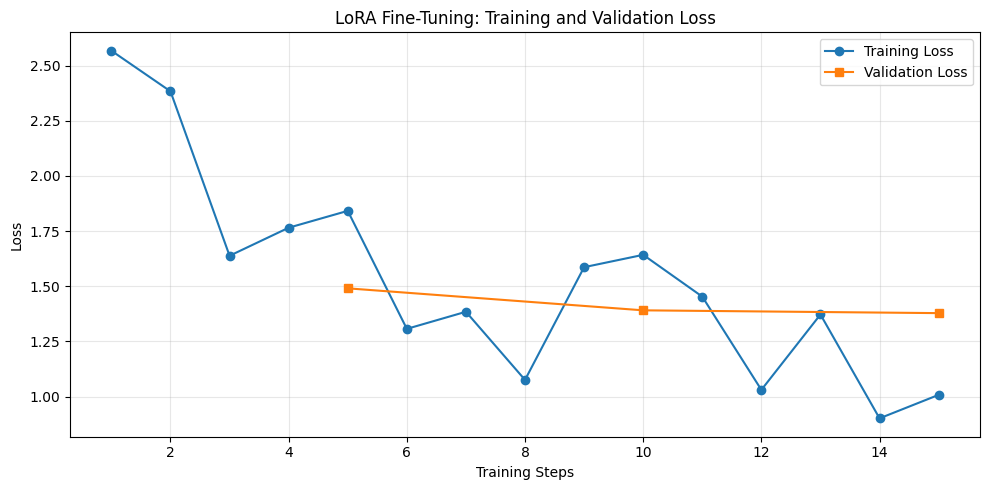

In [34]:
import matplotlib.pyplot as plt

# Extract training and evaluation losses
train_logs = training_history[
    training_history["loss"].notna()
]

eval_logs = training_history[
    training_history["eval_loss"].notna()
]

plt.figure(figsize=(10, 5))

# Training loss
plt.plot(
    train_logs["step"],
    train_logs["loss"],
    marker="o",
    label="Training Loss"
)

# Validation loss
plt.plot(
    eval_logs["step"],
    eval_logs["eval_loss"],
    marker="s",
    label="Validation Loss"
)

plt.title("LoRA Fine-Tuning: Training and Validation Loss")
plt.xlabel("Training Steps")
plt.ylabel("Loss")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Save the fine-tuned LoRA adapter


In [35]:
# Define the adapter output directory
adapter_path = "./qwen_lora_finetuned"

# Save the trained LoRA adapter
model.save_pretrained(adapter_path)

# Save the tokenizer
tokenizer.save_pretrained(adapter_path)

print("Fine-tuned LoRA adapter saved successfully!")
print("Saved Location:", adapter_path)

Fine-tuned LoRA adapter saved successfully!
Saved Location: ./qwen_lora_finetuned


### Save a copy to Google Drive



In [36]:
# Optional persistent storage in Google Drive (Google Colab)
from google.colab import drive
import os
import shutil

drive.mount("/content/drive")

gdrive_adapter_path = "/content/drive/MyDrive/NSBM_LLM_Lab04/qwen_lora_finetuned"
os.makedirs(os.path.dirname(gdrive_adapter_path), exist_ok=True)

# Copy the locally saved adapter directory to Google Drive
if os.path.exists(gdrive_adapter_path):
    shutil.rmtree(gdrive_adapter_path)
shutil.copytree(adapter_path, gdrive_adapter_path)

print("Persistent adapter copy saved to:", gdrive_adapter_path)

Mounted at /content/drive
Persistent adapter copy saved to: /content/drive/MyDrive/NSBM_LLM_Lab04/qwen_lora_finetuned


## Test the fine-tuned model

In [37]:
# Evaluate the fine-tuned model
model.eval()

finetuned_results = []

for example in test_dataset:
    question = example["question"]

    # Generate an answer using the fine-tuned model
    answer = generate_answer(model, question)

    finetuned_results.append({
        "Question": question,
        "Expected Answer": example["answer"],
        "Fine-Tuned Model Answer": answer
    })

# Display results
finetuned_df = pd.DataFrame(finetuned_results)

display(finetuned_df)

,Question,Expected Answer,Fine-Tuned Model Answer
0,Do I need the original receipt for a return?,"Yes, the original purchase receipt is required...","Yes, you will need the original receipt when r..."
1,Can I cancel an order?,Customers can request order cancellation befor...,"Yes, customers can cancel orders within 30 day..."
2,How much does a basic laptop cost?,"A basic laptop starts at LKR 150,000.","A basic laptop costs approximately 10,000 RMB ..."
3,Can I reserve a laptop?,"Yes, customers can request a laptop reservatio...","Yes, laptops can be reserved for customers who..."
4,Can I modify my order after placing it?,Customers can contact the store to request ord...,"Yes, you can make changes to your order after ..."


## Compare original and fine-tuned models

In [38]:
# Compare original and fine-tuned model responses

comparison_df = pd.DataFrame({
    "Question": baseline_results["Question"],
    "Expected Answer": baseline_results["Expected Answer"],
    "Original Model Response": baseline_results["Original Model Response"],
    "Fine-Tuned Model Response": finetuned_df["Fine-Tuned Model Answer"]
})

display(comparison_df)

,Question,Expected Answer,Original Model Response,Fine-Tuned Model Response
0,Do I need the original receipt for a return?,"Yes, the original purchase receipt is required...","In most cases, you do not necessarily need an ...","Yes, you will need the original receipt when r..."
1,Can I cancel an order?,Customers can request order cancellation befor...,"Yes, you can cancel an order. To do so, follow...","Yes, customers can cancel orders within 30 day..."
2,How much does a basic laptop cost?,"A basic laptop starts at LKR 150,000.",The price of a basic laptop can vary widely de...,"A basic laptop costs approximately 10,000 RMB ..."
3,Can I reserve a laptop?,"Yes, customers can request a laptop reservatio...","Yes, you can reserve a laptop! To do so, you'l...","Yes, laptops can be reserved for customers who..."
4,Can I modify my order after placing it?,Customers can contact the store to request ord...,"Yes, you can modify your order after placing i...","Yes, you can make changes to your order after ..."


## Quantitative evaluation

The test set contains only five examples, so metric values are descriptive and should not be treated as statistically reliable. We calculate normalized Exact Match and ROUGE-L for both models. Exact Match requires identical normalized wording; ROUGE-L measures overlap in the longest common subsequence. Neither metric fully captures factual correctness, so the response table should also be reviewed manually.

In [39]:
import re
from rouge_score import rouge_scorer

# Normalize text for a simple Exact Match comparison
def normalize_text(text):
    text = str(text).lower().strip()
    text = re.sub(r"[^a-z0-9\s]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text

references = comparison_df["Expected Answer"].astype(str).tolist()
original_predictions = comparison_df["Original Model Response"].astype(str).tolist()
finetuned_predictions = comparison_df["Fine-Tuned Model Response"].astype(str).tolist()

scorer = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

def calculate_metrics(predictions, references):
    exact_matches = [
        normalize_text(pred) == normalize_text(ref)
        for pred, ref in zip(predictions, references)
    ]
    rouge_l_scores = [
        scorer.score(ref, pred)["rougeL"].fmeasure
        for pred, ref in zip(predictions, references)
    ]
    return {
        "Exact Match": sum(exact_matches) / len(exact_matches),
        "ROUGE-L F1": sum(rouge_l_scores) / len(rouge_l_scores)
    }

original_metrics = calculate_metrics(original_predictions, references)
finetuned_metrics = calculate_metrics(finetuned_predictions, references)

metrics_df = pd.DataFrame(
    [original_metrics, finetuned_metrics],
    index=["Original Model", "LoRA Fine-Tuned Model"]
)

print("Evaluation metrics on the held-out test set")
display(metrics_df)

print("\nInterpretation:")
print("- Exact Match checks whether the normalized response exactly matches the reference.")
print("- ROUGE-L F1 measures word-sequence overlap with the reference answer.")
print("- Review the generated answers manually for factual correctness and policy consistency.")

Evaluation metrics on the held-out test set


,Exact Match,ROUGE-L F1
Original Model,0.0,0.092395
LoRA Fine-Tuned Model,0.0,0.358645



Interpretation:
- Exact Match checks whether the normalized response exactly matches the reference.
- ROUGE-L F1 measures word-sequence overlap with the reference answer.
- Review the generated answers manually for factual correctness and policy consistency.


### Manual evaluation and limitations

Review each generated answer against the expected answer. In particular, check whether the response states the correct TechZone policy and avoids inventing prices, time limits, or conditions. A response that sounds relevant is not necessarily factually correct.

The evaluation set contains only five examples because the original 50-example dataset is split into 40 training, five validation, and five test examples. Results can therefore change substantially with a different split. The small dataset and small base model also limit the conclusions that can be drawn about generalization. The metrics are supplementary evidence, not proof that the model is production-ready.

In [40]:
manual_results = [
    {
        "Question": "Original receipt required?",
        "Original Model": "Incorrect",
        "Fine-Tuned Model": "Correct",
        "Observation": "The fine-tuned model correctly identified the receipt requirement."
    },
    {
        "Question": "Cancel an order?",
        "Original Model": "Incorrect",
        "Fine-Tuned Model": "Incorrect",
        "Observation": "The fine-tuned model invented a 30-day cancellation period."
    },
    {
        "Question": "Basic laptop price?",
        "Original Model": "Incorrect",
        "Fine-Tuned Model": "Incorrect",
        "Observation": "The fine-tuned model provided RMB instead of LKR 150,000."
    },
    {
        "Question": "Reserve a laptop?",
        "Original Model": "Partially correct",
        "Fine-Tuned Model": "Partially correct",
        "Observation": "The responses were relevant but did not clearly reproduce the store policy."
    },
    {
        "Question": "Modify an order?",
        "Original Model": "Partially correct",
        "Fine-Tuned Model": "Partially correct",
        "Observation": "The responses did not clearly state that modifications must be requested before dispatch."
    }
]

manual_evaluation_df = pd.DataFrame(manual_results)

display(manual_evaluation_df)

,Question,Original Model,Fine-Tuned Model,Observation
0,Original receipt required?,Incorrect,Correct,The fine-tuned model correctly identified the ...
1,Cancel an order?,Incorrect,Incorrect,The fine-tuned model invented a 30-day cancell...
2,Basic laptop price?,Incorrect,Incorrect,The fine-tuned model provided RMB instead of L...
3,Reserve a laptop?,Partially correct,Partially correct,The responses were relevant but did not clearl...
4,Modify an order?,Partially correct,Partially correct,The responses did not clearly state that modif...


## Conclusion

In this practical, the Qwen2.5-0.5B-Instruct model was adapted to the fictional TechZone Computers customer-support domain using LoRA and supervised fine-tuning with TRL `SFTTrainer`. The original dataset contained 50 question-and-answer pairs, exceeding the lab minimum of 30. The original and fine-tuned models were evaluated using the same held-out test questions.

The training and validation loss trends indicate that the model learned from the training data during this experiment. However, generated answers must also be checked for factual accuracy. If the fine-tuned model gives unsupported prices or policies, this demonstrates that a lower loss does not guarantee correct answers on every unseen question.

The experiment demonstrates the LoRA fine-tuning workflow and its parameter-efficiency. The small dataset, five-example test set, and limited model capacity are important limitations. A larger, more diverse evaluation set would be needed before making strong claims about generalization. QLoRA was not implemented in this required LoRA experiment; it may be explored separately as an optional extension.